# Experimento en MLflow: búsqueda de hiperparámetros con Optuna

En AMq1 elegimos **XGBoost** para predecir `Burnout_Risk_Level` (Low / Medium / High) y lo
ajustamos con 40 pruebas de Optuna, mirando el F1 macro en validación cruzada. Acá repetimos esa
búsqueda, pero **registrando cada prueba en MLflow**: es uno de los requisitos mínimos del TP
("un experimento en MLflow de búsqueda de hiperparámetros").

Qué queda en MLflow, dentro del experimento **Burnout Risk**:

- un run padre `optuna_search` con la configuración de la búsqueda, el gráfico de la historia y
  las métricas de test del mejor modelo;
- un run hijo por prueba (`tags.stage = 'optuna'`) con sus hiperparámetros y su F1 macro en CV;
- el modelo final registrado como `burnout_model_prod`, con alias `champion`.

**Dónde corre.** El notebook detecta solo si está levantado el entorno de Docker
(MLflow en `localhost:5001` y MinIO en `localhost:9000`). Si no lo está, usa un MLflow local
(SQLite en `notebooks/_salidas/`) y el CSV del repo, así se puede probar sin Docker.

## 1. Configuración

In [1]:
import os
import sys
from pathlib import Path

import requests

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))  # paquete del TP (también sirve `pip install -e .`)

DOCKER_MLFLOW = "http://localhost:5001"


def docker_levantado() -> bool:
    """True si responde el MLflow del docker-compose."""
    try:
        return requests.get(f"{DOCKER_MLFLOW}/health", timeout=2).ok
    except requests.RequestException:
        return False


MODO = "docker" if docker_levantado() else "local"

if MODO == "docker":
    # Credenciales y endpoint de MinIO (los mismos del archivo .env del repo)
    os.environ["AWS_ACCESS_KEY_ID"] = "minio"
    os.environ["AWS_SECRET_ACCESS_KEY"] = "minio123"
    os.environ["MLFLOW_S3_ENDPOINT_URL"] = "http://localhost:9000"
    os.environ["AWS_ENDPOINT_URL_S3"] = "http://localhost:9000"
    TRACKING_URI = DOCKER_MLFLOW
else:
    SALIDAS = ROOT / "notebooks" / "_salidas"
    SALIDAS.mkdir(exist_ok=True)
    TRACKING_URI = f"sqlite:///{(SALIDAS / 'mlflow.db').as_posix()}"

print(f"Modo: {MODO}  ·  MLflow: {TRACKING_URI}")

Modo: local  ·  MLflow: sqlite:///C:/Users/USUARIO/CEIA/MLOps-TP-AVS/notebooks/_salidas/mlflow.db


In [2]:
import matplotlib.pyplot as plt
import mlflow
import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_score

from burnout.config import BEST_PARAMS_AMQ1, EXPERIMENT_NAME, SEED
from burnout.model import make_pipeline, test_metrics
from burnout.train import log_and_register

N_TRIALS = 40  # igual que en AMq1: con la misma semilla, la búsqueda se reproduce
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)
SCORING = "f1_macro"

optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_tracking_uri(TRACKING_URI)
experiment = mlflow.set_experiment(EXPERIMENT_NAME)
print(f"Experimento '{EXPERIMENT_NAME}' (id {experiment.experiment_id})")

2026/11/11 11:53:03 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/11 11:53:03 INFO mlflow.store.db.utils: Updating database tables


2026/11/11 11:53:04 INFO mlflow.tracking.fluent: Experiment with name 'Burnout Risk' does not exist. Creating a new experiment.


Experimento 'Burnout Risk' (id 1)


## 2. Datos
Con Docker leemos el split que dejó el DAG `etl_burnout` en MinIO; sin Docker, generamos el mismo
split (80/20, estratificado, semilla 42) a partir del CSV.

In [3]:
if MODO == "docker":
    from burnout import storage
    from burnout.config import S3_KEYS

    X_train = storage.read_csv(S3_KEYS["X_train"])
    X_test = storage.read_csv(S3_KEYS["X_test"])
    y_train = storage.read_csv(S3_KEYS["y_train"]).squeeze("columns")
    y_test = storage.read_csv(S3_KEYS["y_test"]).squeeze("columns")
else:
    from burnout.data import load_raw, make_split

    X_train, X_test, y_train, y_test = make_split(load_raw())

print(f"train: {X_train.shape}  test: {X_test.shape}")
X_train.head()

train: (40000, 12)  test: (10000, 12)


,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Paid_Subscription,Year_of_Study,Prompt_Engineering_Skill,Major_Category,Primary_Use_Case,Institutional_Policy
32027,3.452,27.72,4,9.49,4,6,1,Junior,Intermediate,STEM,Debugging/Troubleshooting,Allowed_With_Citation
34830,2.992,1.91,3,9.63,4,6,0,Graduate,Intermediate,Business,Ideation,Allowed_With_Citation
18757,3.185,7.53,1,20.99,4,9,0,Junior,Intermediate,STEM,Debugging/Troubleshooting,Actively_Encouraged
45540,2.916,2.50,3,12.61,4,5,0,Sophomore,Beginner,Arts,Summarizing_Reading,Allowed_With_Citation
22449,3.093,8.44,2,13.95,5,7,0,Sophomore,Beginner,Business,Ideation,Strict_Ban


## 3. Búsqueda con Optuna, registrando cada prueba
El espacio de búsqueda es el mismo de AMq1. Cada prueba abre un run **anidado** (`nested=True`)
dentro del run padre, así en la UI de MLflow se ven agrupadas.

In [4]:
def objective(trial: optuna.Trial) -> float:
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
    }
    with mlflow.start_run(run_name=f"trial_{trial.number:02d}", nested=True, tags={"stage": "optuna"}):
        scores = cross_val_score(make_pipeline(**params), X_train, y_train, cv=CV, scoring=SCORING)
        mlflow.log_params(params)
        mlflow.log_metrics({"cv_f1_macro": scores.mean(), "cv_f1_macro_std": scores.std()})
    return scores.mean()

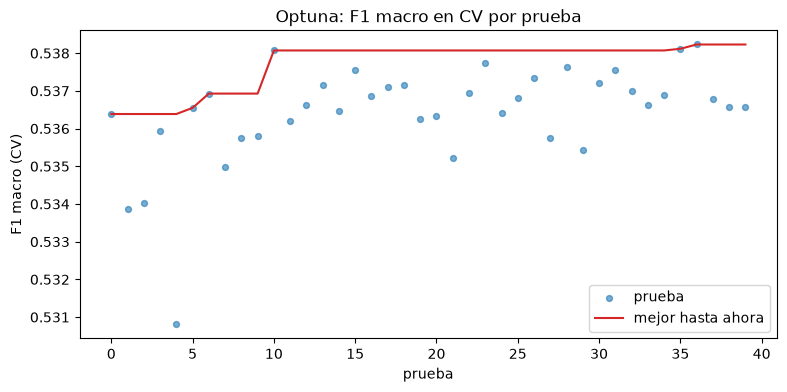

Mejor F1 macro en CV: 0.5382
Mejores hiperparámetros: {'n_estimators': 400, 'learning_rate': 0.08180378706154819, 'max_depth': 4, 'min_child_weight': 5, 'subsample': 0.7945776815049461, 'colsample_bytree': 0.8527732701352171, 'reg_alpha': 0.010164525456925814, 'reg_lambda': 0.0056038422381060006, 'gamma': 2.2925266742668544}


In [5]:
with mlflow.start_run(run_name="optuna_search", tags={"stage": "optuna_parent"}) as parent:
    mlflow.log_params({"n_trials": N_TRIALS, "cv_folds": CV.n_splits, "scoring": SCORING, "sampler": "TPE"})

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS)

    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
    mlflow.log_metric("best_cv_f1_macro", study.best_value)

    # Historia de la búsqueda: cada punto es una prueba; la línea, el mejor hasta ese momento.
    historia = study.trials_dataframe()[["number", "value"]]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.scatter(historia["number"], historia["value"], s=18, alpha=0.6, label="prueba")
    ax.plot(historia["number"], historia["value"].cummax(), color="tab:red", label="mejor hasta ahora")
    ax.set(xlabel="prueba", ylabel="F1 macro (CV)", title="Optuna: F1 macro en CV por prueba")
    ax.legend()
    mlflow.log_figure(fig, "optuna_historia.png")
    plt.show()

print(f"Mejor F1 macro en CV: {study.best_value:.4f}")
print(f"Mejores hiperparámetros: {study.best_params}")

## 4. ¿Reproducimos AMq1?
Usamos la misma semilla, el mismo espacio de búsqueda y las mismas versiones de librerías que en AMq1
(donde el mejor F1 macro en CV fue 0,5385). Aun así, **no esperamos los mismos hiperparámetros**. En
AMq1 XGBoost usó `n_jobs=-1` y ahora usa `XGB_N_JOBS = 4`. Esa diferencia cambia apenas el puntaje de
cada prueba (ver la clase C1, §5), y como TPE elige la próxima prueba según los puntajes anteriores, la
búsqueda toma otro camino. Lo que sí debería mantenerse es el **nivel** del mejor F1 macro en CV,
alrededor de 0,538, porque con estos datos hay un techo.

In [6]:
import pandas as pd

comparacion = pd.DataFrame({"AMq1": BEST_PARAMS_AMQ1, "ahora": study.best_params})
comparacion["igual"] = [
    abs(float(a) - float(b)) < 1e-9 for a, b in zip(comparacion["AMq1"], comparacion["ahora"], strict=True)
]
comparacion

,AMq1,ahora,igual
n_estimators,250.000000,400.000000,False
learning_rate,0.201204,0.081804,False
max_depth,2.000000,4.000000,False
min_child_weight,4.000000,5.000000,False
subsample,0.610519,0.794578,False
colsample_bytree,0.688752,0.852773,False
reg_alpha,0.095296,0.010165,False
reg_lambda,0.010076,0.005604,False
gamma,3.650547,2.292527,False


## 5. Modelo final: entrenar, evaluar en test y registrar como champion

In [7]:
modelo = make_pipeline(**study.best_params).fit(X_train, y_train)
metricas = test_metrics(y_test, modelo.predict(X_test))

with mlflow.start_run(run_id=parent.info.run_id):
    mlflow.log_metrics({f"test_{k}": v for k, v in metricas.items()})

version = log_and_register(modelo, metricas, study.best_params, X_train, TRACKING_URI, run_name="final_from_optuna")
pd.Series(metricas).round(4).to_frame("test")

C:\Users\USUARIO\CEIA\MLOps-TP-AVS\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Successfully registered model 'burnout_model_prod'.
Created version '1' of model 'burnout_model_prod'.


,test
f1_macro,0.5362
balanced_accuracy,0.5232
recall_low,0.4951
recall_medium,0.6101
recall_high,0.4646


In [8]:
print(f"Registrado burnout_model_prod v{version} con alias 'champion'")

# Lo cargamos por alias, como lo hará el DAG de predicción por lotes.
champion = mlflow.sklearn.load_model("models:/burnout_model_prod@champion")
print("Predicción para 3 estudiantes de test:", champion.predict(X_test.head(3)))

Registrado burnout_model_prod v1 con alias 'champion'
Predicción para 3 estudiantes de test: [1 2 1]


## 6. Ver los resultados en la UI de MLflow

- **Con Docker:** abrir http://localhost:5001 → experimento *Burnout Risk*.
- **Sin Docker:** en una terminal, desde la raíz del repo y con el entorno activado:

```bash
mlflow ui --backend-store-uri sqlite:///notebooks/_salidas/mlflow.db --port 5001
```

En la UI conviene seleccionar los runs hijos y usar **Compare → Parallel coordinates** para ver
qué hiperparámetros se asocian con mejor F1 macro.